---
# Task 2.1


In [1]:
# Installation of required libraries (run once per environment)
!pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob

# Download the small English language model for spaCy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum: a single compiled operation over the whole array ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop: ten million interpreted iterations ------------------
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 4999880.55 | Time: 0.01782 sec
Manual Sum: 4999880.55 | Time: 6.29523 sec

NumPy is 353x faster on this machine.


---
# Task 2.2 — Web scraping and data acquisition



In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html'
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
articles = []

for url in urls:
    try:
        # Fetch the page content
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, 'lxml')

        # Extract Title
        title = soup.find('h3', class_='post-title')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        # Extract Body Text
        content_div = soup.find('div', class_='post-body entry-content')
        if not content_div:
            print(f"[SKIP] No content block found: {url}")
            continue

        paragraphs = content_div.find_all('p')
        text = ' '.join(p.get_text(strip=True) for p in paragraphs)

        # Skip short articles for quality control
        if len(text) > 100:
            articles.append({'url': url, 'title': title, 'text': text})
        else:
            print(f"[SKIP] Too short: {url}")

        time.sleep(1)   # Be polite to the server
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} articles.")
df.head()

[SKIP] Too short: https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html

Scraped 4 of 5 articles.


,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [4]:
# Save the raw scrape immediately, so the rest of the lab works offline
# and so your results are reproducible even after the sites change.
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    # Fallback: load a previously saved scrape
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(4, 3)


---
# Task 2.3 — Linguistic feature engineering with spaCy




In [5]:
import spacy
import pandas as pd

# Loads the trained spaCy English model: tokenizer, POS tagger and NER
nlp = spacy.load("en_core_web_sm")

def extract_features(text):
    """Process text with spaCy and extract four linguistic features."""
    doc = nlp(text)
    return pd.Series({
        'num_tokens':    len(doc),                                   # tokens
        'num_sentences': len(list(doc.sents)),                       # sentences
        'num_entities':  len(doc.ents),                              # named entities
        'num_nouns':     len([t for t in doc if t.pos_ == 'NOUN'])   # nouns
    })

if not df.empty:
    features = df['text'].apply(extract_features)
    df = pd.concat([df, features], axis=1)

    # A simple non-spaCy feature for comparison
    df['title_length'] = df['title'].apply(len)

    print("Features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns']].head())
else:
    print("No articles found for feature extraction.")

Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Top 10 AI Tools That Will Transform Your Conte...,1188,47,24,321
1,"LimeWire AI Studio Review 2023: Details, Prici...",1723,65,103,420
2,Top 10 AI Tools in 2023 That Will Make Your Li...,1480,52,39,331
3,Top 10 AI Content Generator & Writer Tools in ...,1319,63,89,271


In [6]:
# Inspect WHAT spaCy actually found, not just how many.
# Reading the entities is how you learn whether the feature is meaningful.

doc = nlp(df['text'].iloc[0][:1500])

print("First 15 named entities in article 1:\n")
for ent in list(doc.ents)[:15]:
    print(f"  {ent.text:<35} {ent.label_:<12} ({spacy.explain(ent.label_)})")

First 15 named entities in article 1:

  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  GPE          (Countries, cities, states)
  10                                  CARDINAL     (Numerals that do not fall under another type)
  AI                                  GPE          (Countries, cities, states)
  2025                                DATE         (Absolute or relative dates or periods)
  AI                                  GPE          (Countries, cities, states)
  Dive Into the Top 10                WORK_OF_ART  (Titles of books, songs, etc.)
  2025                                DATE         (Absolute or relative dates or periods)
  Magic Studio                        PERSON       (People, including fictional)
  AI                                  ORG          (Companies, agencies, institutions, etc.)


In [7]:
from textblob import TextBlob

def get_sentiment(text):
    """Polarity in [-1, 1]; subjectivity in [0, 1]."""
    blob = TextBlob(text)
    return pd.Series({
        'sentiment_polarity':     blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

if not df.empty:
    sentiment_features = df['text'].apply(get_sentiment)
    df = pd.concat([df, sentiment_features], axis=1)

    print("Sentiment features extracted successfully.\n")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']])

Sentiment features extracted successfully.



,title,sentiment_polarity,sentiment_subjectivity
0,Top 10 AI Tools That Will Transform Your Conte...,0.229493,0.583603
1,"LimeWire AI Studio Review 2023: Details, Prici...",0.219387,0.573587
2,Top 10 AI Tools in 2023 That Will Make Your Li...,0.197417,0.436441
3,Top 10 AI Content Generator & Writer Tools in ...,0.214853,0.564907


In [8]:
# Persist the fully engineered table -- this is the Lab 02 deliverable.
df.to_csv("articles.csv", index=False)
print("Saved articles.csv with", df.shape[1], "columns:")
print(list(df.columns))

Saved articles.csv with 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


---
# Task 2.4 — Exploratory Data Analysis


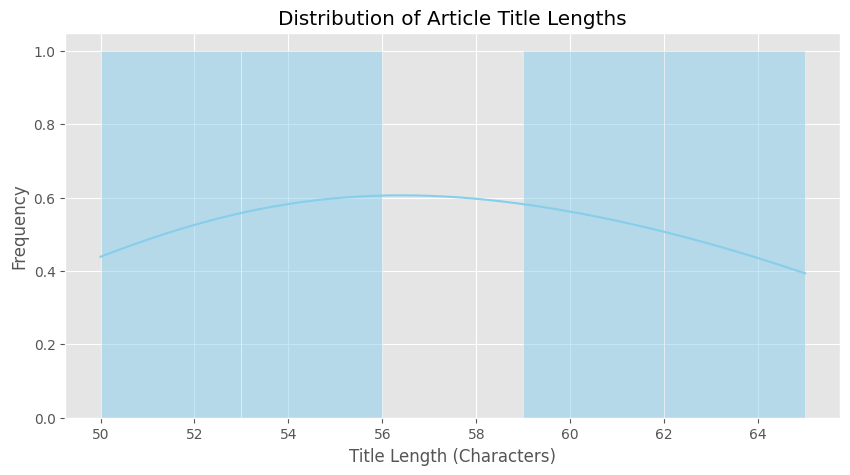

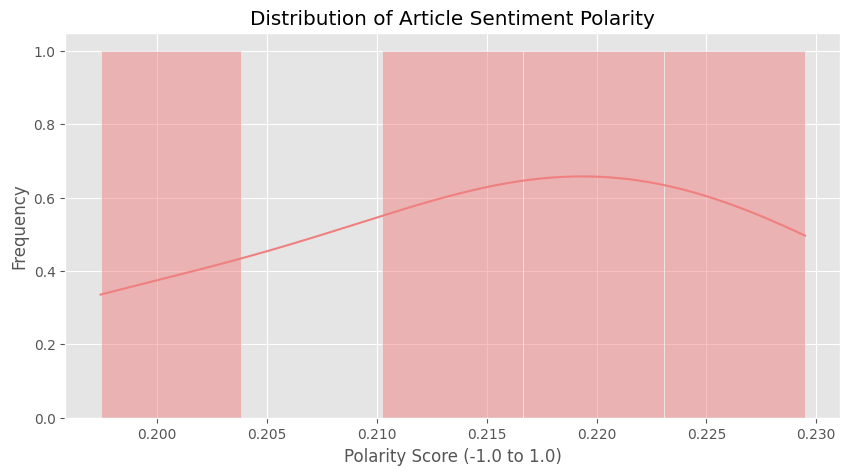

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.show()

## B. Pairwise relationships between the derived numeric features

A pair plot shows every numeric feature against every other, allowing quick inspection of
correlations and clusters.

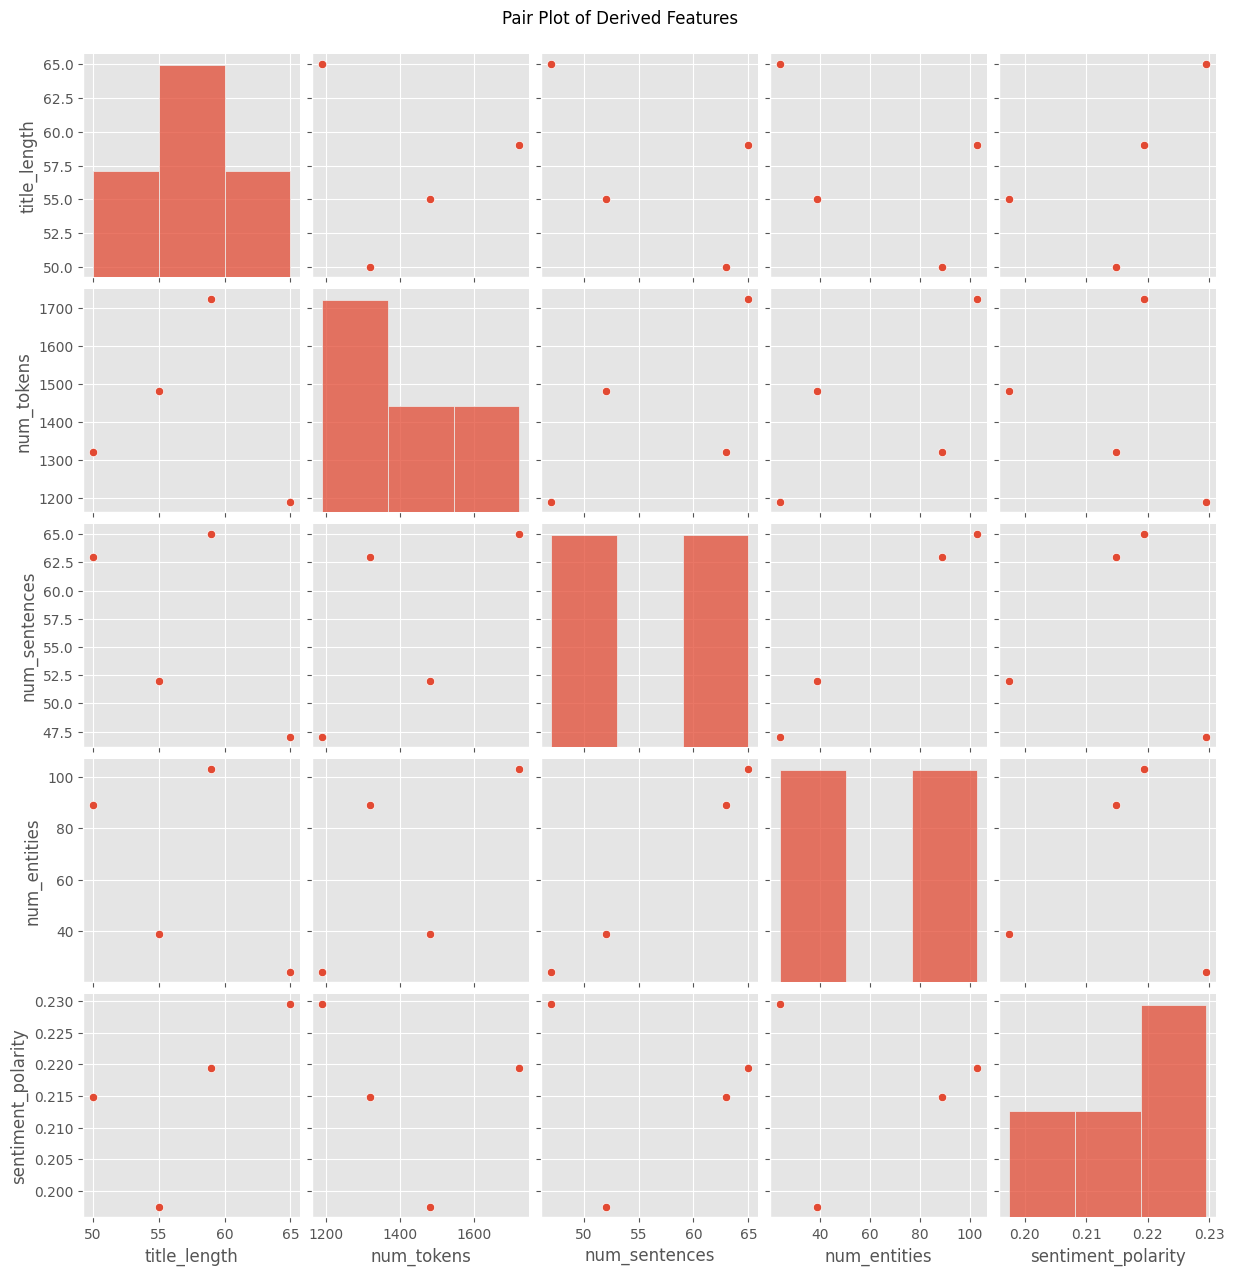

In [10]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.show()

In [11]:
# The same information as numbers. With five articles this is indicative only.
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:



,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,1.00,-0.15,-0.58,-0.50,0.63
num_tokens,-0.15,1.00,0.64,0.65,-0.33
num_sentences,-0.58,0.64,1.00,1.00,-0.06
num_entities,-0.50,0.65,1.00,1.00,0.02
sentiment_polarity,0.63,-0.33,-0.06,0.02,1.00


## C. Advanced text feature — TF–IDF analysis



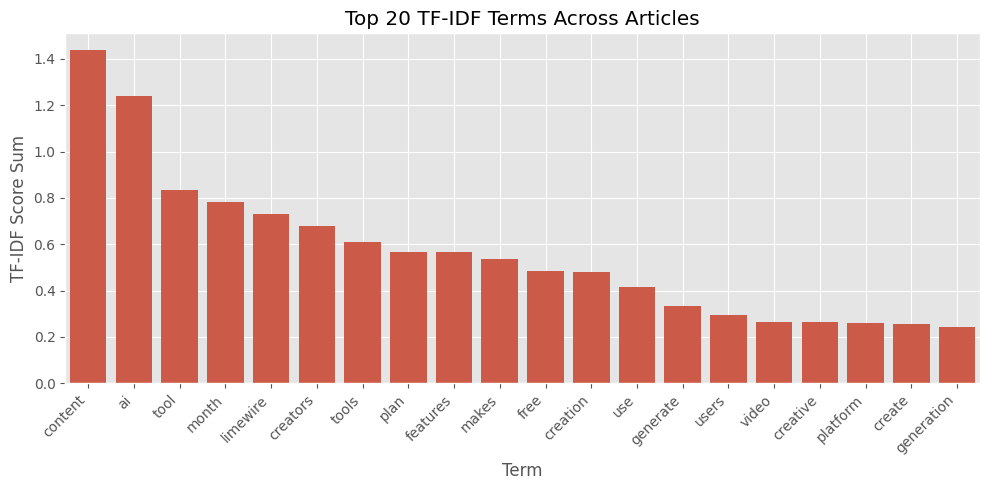

Sparse matrix shape (documents x terms): (4, 20)


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# stop_words='english' discards 'the', 'a', ...; max_features keeps the top 20
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum each term's score across all documents to rank global importance
tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)

,title,num_tokens,num_sentences,num_entities,num_nouns,num_verbs,avg_sentence_length
0,Top 10 AI Tools That Will Transform Your Conte...,1188.0,47.0,24.0,321.0,150.0,25.276596
1,"LimeWire AI Studio Review 2023: Details, Prici...",1723.0,65.0,103.0,420.0,200.0,26.507692
2,Top 10 AI Tools in 2023 That Will Make Your Li...,1480.0,52.0,39.0,331.0,166.0,28.461538
3,Top 10 AI Content Generator & Writer Tools in ...,1319.0,63.0,89.0,271.0,140.0,20.936508


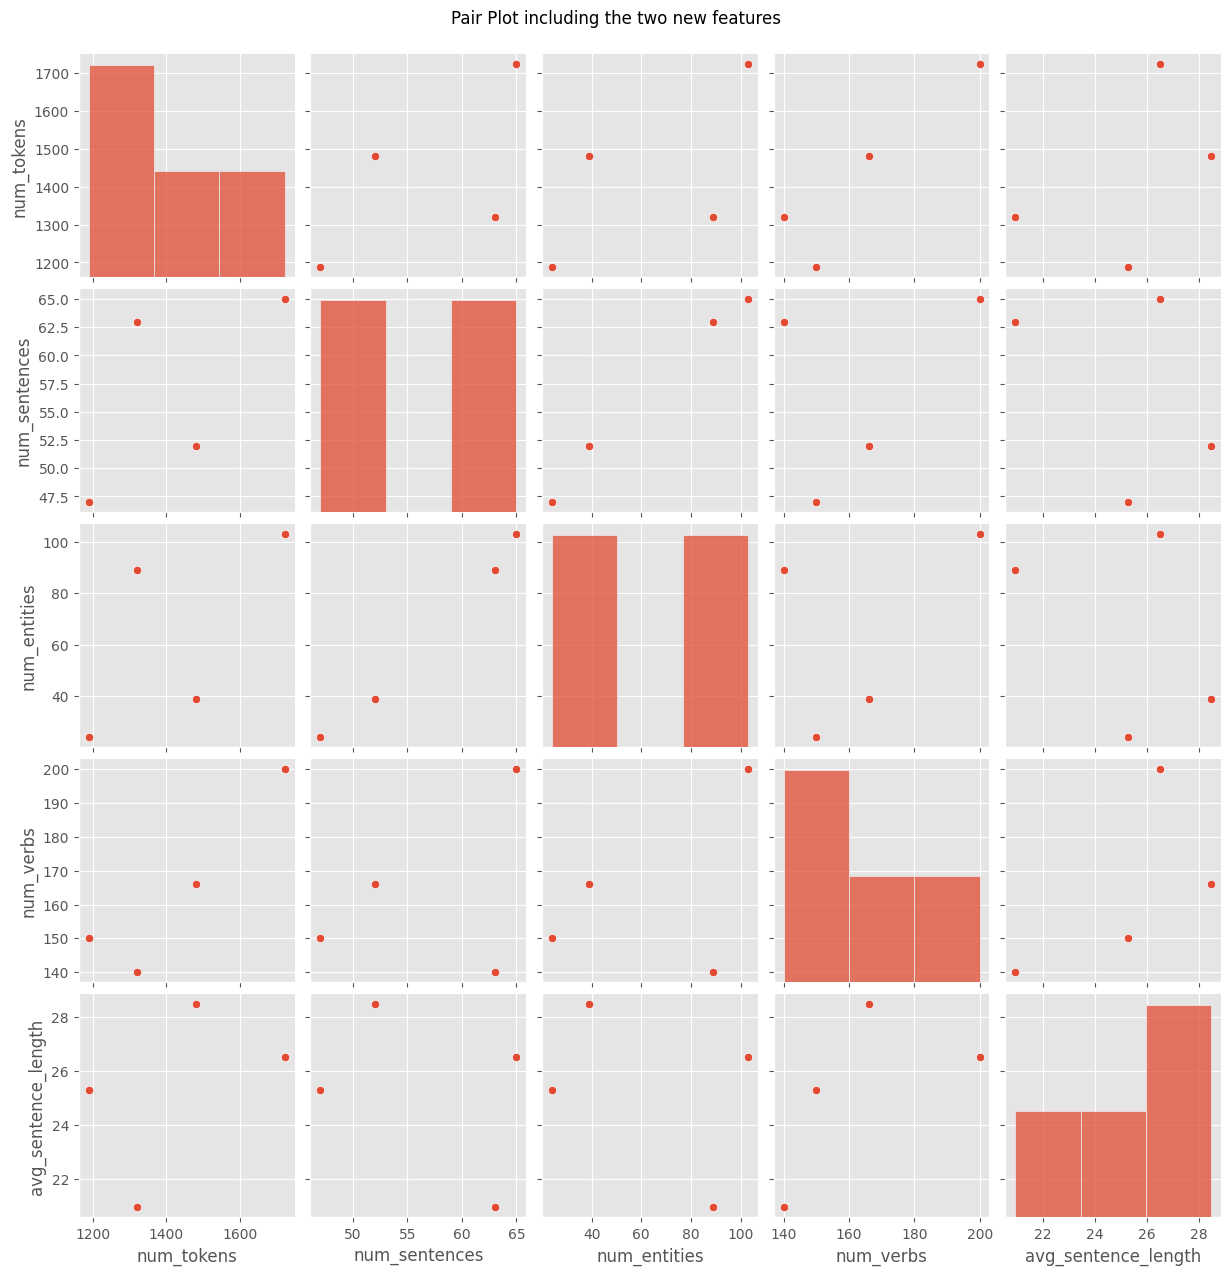

In [13]:
# --- Exercise 2: extended feature extraction -----------------------------

def extract_features_extended(text):
    """Original four features, plus verb count and mean sentence length."""
    doc = nlp(text)
    sentences = list(doc.sents)
    return pd.Series({
        'num_tokens':          len(doc),
        'num_sentences':       len(sentences),
        'num_entities':        len(doc.ents),
        'num_nouns':           len([t for t in doc if t.pos_ == 'NOUN']),
        'num_verbs':           len([t for t in doc if t.pos_ == 'VERB']),
        'avg_sentence_length': (len(doc) / len(sentences)) if sentences else 0.0,
    })


extended = df['text'].apply(extract_features_extended)
df_ext = pd.concat([df[['title']], extended], axis=1)
display(df_ext)

sns.pairplot(df_ext[['num_tokens', 'num_sentences', 'num_entities',
                     'num_verbs', 'avg_sentence_length']])
plt.suptitle('Pair Plot including the two new features', y=1.02)
plt.show()

In [14]:
# --- Exercise 4: TF-IDF with and without stop-word removal ---------------

vec_stop = TfidfVectorizer(stop_words='english', max_features=20)
vec_none = TfidfVectorizer(stop_words=None,      max_features=20)

top_stop = (pd.DataFrame(vec_stop.fit_transform(df['text']).toarray(),
                         columns=vec_stop.get_feature_names_out())
              .sum().sort_values(ascending=False))
top_none = (pd.DataFrame(vec_none.fit_transform(df['text']).toarray(),
                         columns=vec_none.get_feature_names_out())
              .sum().sort_values(ascending=False))

comparison = pd.DataFrame({
    "with stop_words='english'": top_stop.index,
    "with stop_words=None":      top_none.index,
})
display(comparison)

print("\nTerms that appear ONLY when stop words are kept:")
print(sorted(set(top_none.index) - set(top_stop.index)))

,with stop_words='english',with stop_words=None
0,content,and
1,ai,the
2,tool,to
3,month,for
4,limewire,content
5,creators,it
6,tools,of
7,plan,ai
8,features,month
9,makes,you



Terms that appear ONLY when stop words are kept:
['and', 'as', 'can', 'for', 'in', 'is', 'it', 'of', 'that', 'the', 'to', 'with', 'you', 'your']


---
#  Assignment



In [16]:
import re

def get_urls_from_sitemap(sitemap_url, n=10):
    res = requests.get(sitemap_url, headers=headers, timeout=10)
    res.raise_for_status()
    urls = re.findall(r"<loc>(.*?)</loc>", res.text)
    return urls[:n]

# Blog A (Blogspot)
urls_a = get_urls_from_sitemap("https://techncruncher.blogspot.com/sitemap.xml", n=10)
print(len(urls_a))
for u in urls_a: print(u)

10
https://techncruncher.blogspot.com/2025/12/how-i-get-free-traffic-from-chatgpt-in.html
https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html
https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html
https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html
https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html
https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html
https://techncruncher.blogspot.com/2022/07/top-10-ai-marketing-tools-you-should-use.html
https://techncruncher.blogspot.com/2022/06/most-frequently-asked-questions-about.html
https://techncruncher.blogspot.com/2022/04/what-is-blockchain-everything-you-need.html
https://techncruncher.blogspot.com/2022/03/prowritingaid-vs-grammarly-which.html


In [19]:
# --- assignment --------------------------------------------
SOURCE_A = {
    "name": "techncruncher",
    "urls": urls_a,                       # Automatically using your 10 URLs from the previous cell
    "title_css":   "h3.post-title",
    "content_css": "div.post-body.entry-content",
}

SOURCE_B = {
    "name": "blog-b-name",
    "urls": [],                           # Replace with your 10 URLs for Blog B to scrape it
    "title_css":   "h1.entry-title",       # typical WordPress, verify below
    "content_css": "div.entry-content",    # typical WordPress, verify below
}

def scrape_source(source):
    rows = []
    for url in source["urls"]:
        try:
            res = requests.get(url, headers=headers, timeout=10)
            res.raise_for_status()
            soup = BeautifulSoup(res.content, "lxml")

            t = soup.select_one(source["title_css"])
            title = t.get_text(strip=True) if t else soup.title.get_text(strip=True)

            block = soup.select_one(source["content_css"])
            if not block:
                print(f"[SKIP] selector missed: {url}")
                continue
            text = " ".join(p.get_text(strip=True) for p in block.find_all("p"))

            if len(text) > 100:
                rows.append({"source": source["name"], "url": url,
                             "title": title, "text": text})
            else:
                print(f"[SKIP] too short: {url}")
            time.sleep(1)
        except Exception as e:
            print(f"[ERROR] {url} -> {e}")
    return pd.DataFrame(rows)

corpus = pd.concat([scrape_source(SOURCE_A), scrape_source(SOURCE_B)], ignore_index=True)
corpus.to_csv("two_source_corpus.csv", index=False)
if not corpus.empty:
    print(corpus.groupby("source").size())
else:
    print("Corpus is empty. Please ensure you have configured valid URLs for both sources.")

[SKIP] too short: https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html
source
techncruncher    9
dtype: int64
